# 05. Transfer learning, efficiency, and classical versus CNN

Questions: *does ImageNet pretraining help on 1,260 grayscale steel images, how deep should
fine-tuning go, what does each model cost to run, how much data does each approach need, and when is
a handcrafted pipeline the better choice?*

ResNet-18, DenseNet-121 and MobileNetV2 start from ImageNet weights (torchvision). The grayscale image
is repeated into three channels and ImageNet-normalized inside the model. **Frozen**: only a new head is
trained; **partial**: the last stage too; **full**: every layer, pretrained layers ten times slower than
the head. Same recipe and five seeds as every other CNN.

In [1]:
import csv, json, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image, display

from idefect.config import load_config
from idefect.models.registry import display_name

cfg = load_config("configs/neu_baseline.yaml")
RES = Path(cfg.output.results_dir)
FIG = Path(cfg.output.figures_dir)


def show(path):
    # Display a saved figure at full resolution.
    display(Image(filename=str(path)))


def seeds_table(stems):
    rows = []
    for stem in stems:
        m = json.loads((RES / f"{stem}_metrics.json").read_text())
        s = m["seed_summary"]
        rows.append({"model": m["display_name"], "trained params": m["n_params"],
                     "total params": m.get("n_params_total", m["n_params"]),
                     "test macro-F1 mean": s["test_macro_f1"]["mean"], "test std": s["test_macro_f1"]["std"],
                     "test min": s["test_macro_f1"]["min"], "test max": s["test_macro_f1"]["max"],
                     "val macro-F1 mean": s["val_macro_f1"]["mean"],
                     "seconds per seed": s["train_time_sec"]["mean"]})
    return pd.DataFrame(rows).set_index("model").round(4)

seeds_table(['resnet18_imagenet_frozen', 'resnet18_imagenet_partial', 'resnet18_imagenet_full', 'densenet121_imagenet_frozen', 'densenet121_imagenet_partial', 'densenet121_imagenet_full', 'mobilenet_v2_imagenet_frozen', 'mobilenet_v2_imagenet_partial', 'mobilenet_v2_imagenet_full'])

,trained params,total params,test macro-F1 mean,test std,test min,test max,val macro-F1 mean,seconds per seed
model,,,,,,,,
"ResNet-18 (ImageNet, frozen)",3078,11179590,0.9630,0.0031,0.9587,0.9661,0.9679,52.124
"ResNet-18 (ImageNet, partial)",8396806,11179590,0.9940,0.0033,0.9888,0.9963,0.9993,63.798
"ResNet-18 (ImageNet, full)",11179590,11179590,0.9978,0.0020,0.9963,1.0000,1.0000,112.480
"DenseNet-121 (ImageNet, frozen)",6150,6960006,0.9764,0.0041,0.9696,0.9809,0.9896,148.192
"DenseNet-121 (ImageNet, partial)",2166278,6960006,0.9962,0.0065,0.9849,1.0000,0.9963,167.652
"DenseNet-121 (ImageNet, full)",6960006,6960006,1.0000,0.0000,1.0000,1.0000,1.0000,355.278
"MobileNetV2 (ImageNet, frozen)",7686,2231558,0.9794,0.0060,0.9730,0.9849,0.9762,45.940
"MobileNetV2 (ImageNet, partial)",1689030,2231558,0.9970,0.0017,0.9962,1.0000,1.0000,58.890
"MobileNetV2 (ImageNet, full)",2231558,2231558,0.9940,0.0043,0.9887,1.0000,1.0000,122.512


Findings:

* **Pretraining is the largest single gain of the project.** Fully fine-tuned DenseNet-121 classifies all
  269 test images correctly in all five seeds (validation 1.0000 in every seed too; seeds and
  checkpoints were chosen on validation). Fully fine-tuned ResNet-18 (0.9978) and partially fine-tuned
  MobileNetV2 (0.9970) are within one test image.
* **Frozen ImageNet features are not enough** (0.963 to 0.979): natural-image features describe steel
  texture poorly until they are adapted.
* **How much to unfreeze depends on the backbone.** ResNet-18 and DenseNet-121 improve at every step;
  MobileNetV2 is best partially fine-tuned, a tie with full fine-tuning within one standard deviation.

## The image no NEU-only model can classify: `Sc_44.bmp`, across all seeds

In [2]:
def sc44(stem):
    base = RES / "cnn_runs" / ("" if stem == "custom_cnn" else stem)
    hits = []
    for f in sorted(base.glob(f"seed*/{stem}_test_predictions.csv")):
        row = next(r for r in csv.DictReader(open(f)) if r["path"].endswith("Sc_44.bmp"))
        hits.append(row["pred"] == "scratches")
    return sum(hits), len(hits)

pd.DataFrame([{"model": display_name(*(s.rsplit("_", 1) if "imagenet" in s else (s, "full"))),
               "Sc_44 correct (seeds)": "%d of %d" % sc44(s)} for s in ['custom_cnn', 'vgg', 'resnet', 'densenet', 'mobilenet', 'resnet18_imagenet_frozen', 'resnet18_imagenet_partial', 'resnet18_imagenet_full', 'densenet121_imagenet_frozen', 'densenet121_imagenet_partial', 'densenet121_imagenet_full', 'mobilenet_v2_imagenet_frozen', 'mobilenet_v2_imagenet_partial', 'mobilenet_v2_imagenet_full']]).set_index("model")

,Sc_44 correct (seeds)
model,
Custom CNN,0 of 5
VGG-style CNN,0 of 5
ResNet-18 (scratch),0 of 5
DenseNet-BC (scratch),0 of 5
MobileNetV2 (scratch),0 of 5
"ResNet-18 (ImageNet, frozen)",0 of 5
"ResNet-18 (ImageNet, partial)",5 of 5
"ResNet-18 (ImageNet, full)",3 of 5
"DenseNet-121 (ImageNet, frozen)",4 of 5


No scratch CNN gets it right in any seed (0 of 25); the ImageNet models do in 33 of 45 runs.

## Efficiency (laptop RTX 5070 GPU, 16-thread CPU)

In [3]:
eff = json.loads((RES / "efficiency.json").read_text())
print(f"preprocessing (resize + CLAHE): {eff['preprocess_ms']:.2f} ms per image")
cols = ["display_name", "params_total", "size_mb", "cpu_latency_ms", "cpu_latency_range_ms", "gpu_latency_ms",
        "gpu_throughput_ips", "gpu_train_peak_mb", "train_time_sec", "test_macro_f1"]
pd.DataFrame(eff["rows"])[cols].set_index("display_name").round(3)

preprocessing (resize + CLAHE): 0.16 ms per image


,params_total,size_mb,cpu_latency_ms,cpu_latency_range_ms,gpu_latency_ms,gpu_throughput_ips,gpu_train_peak_mb,train_time_sec,test_macro_f1
display_name,,,,,,,,,
HOG + LBP + GLCM + Random Forest,NaN,5.418,22.729,"[22.675770002024365, 22.821600001407205]",NaN,NaN,NaN,27.651,0.907
HOG + LBP + GLCM + XGBoost,NaN,1.771,14.098,"[14.02451200010546, 14.19195099879289]",NaN,NaN,NaN,4.321,0.945
LBP + GLCM + Decision Tree,NaN,0.009,8.976,"[8.869843499269336, 9.088536999115604]",NaN,NaN,NaN,0.048,0.922
LBP + GLCM + k-NN,NaN,0.504,9.189,"[9.136196500548976, 9.55947849979566]",NaN,NaN,NaN,0.001,0.940
LBP + GLCM + Logistic Regression,NaN,0.009,9.010,"[8.948401498855674, 9.208002000377746]",NaN,NaN,NaN,0.014,0.989
LBP + GLCM + SVM,NaN,0.171,9.031,"[8.997764998639468, 9.230354500687099]",NaN,NaN,NaN,0.037,0.985
Custom CNN,93670.0,0.367,1.340,"[1.331416498942417, 1.4327379994938383]",0.520,9908.529,688.008,76.848,0.989
DenseNet-BC (scratch),773638.0,3.165,15.525,"[12.599626501469174, 16.418529499787837]",5.018,1077.802,4456.112,490.122,0.996
"DenseNet-121 (ImageNet, frozen)",6960006.0,27.148,17.982,"[17.0442019989423, 21.948309999061166]",12.944,1661.819,242.000,148.192,0.977


Batch-1 latency drifts by up to about 40 percent between rounds, so it is the median of five
interleaved rounds (range shown); frozen, partial and full variants of one backbone are the same
network at inference, so their spread is measurement noise. Batch-64 throughput is stable.

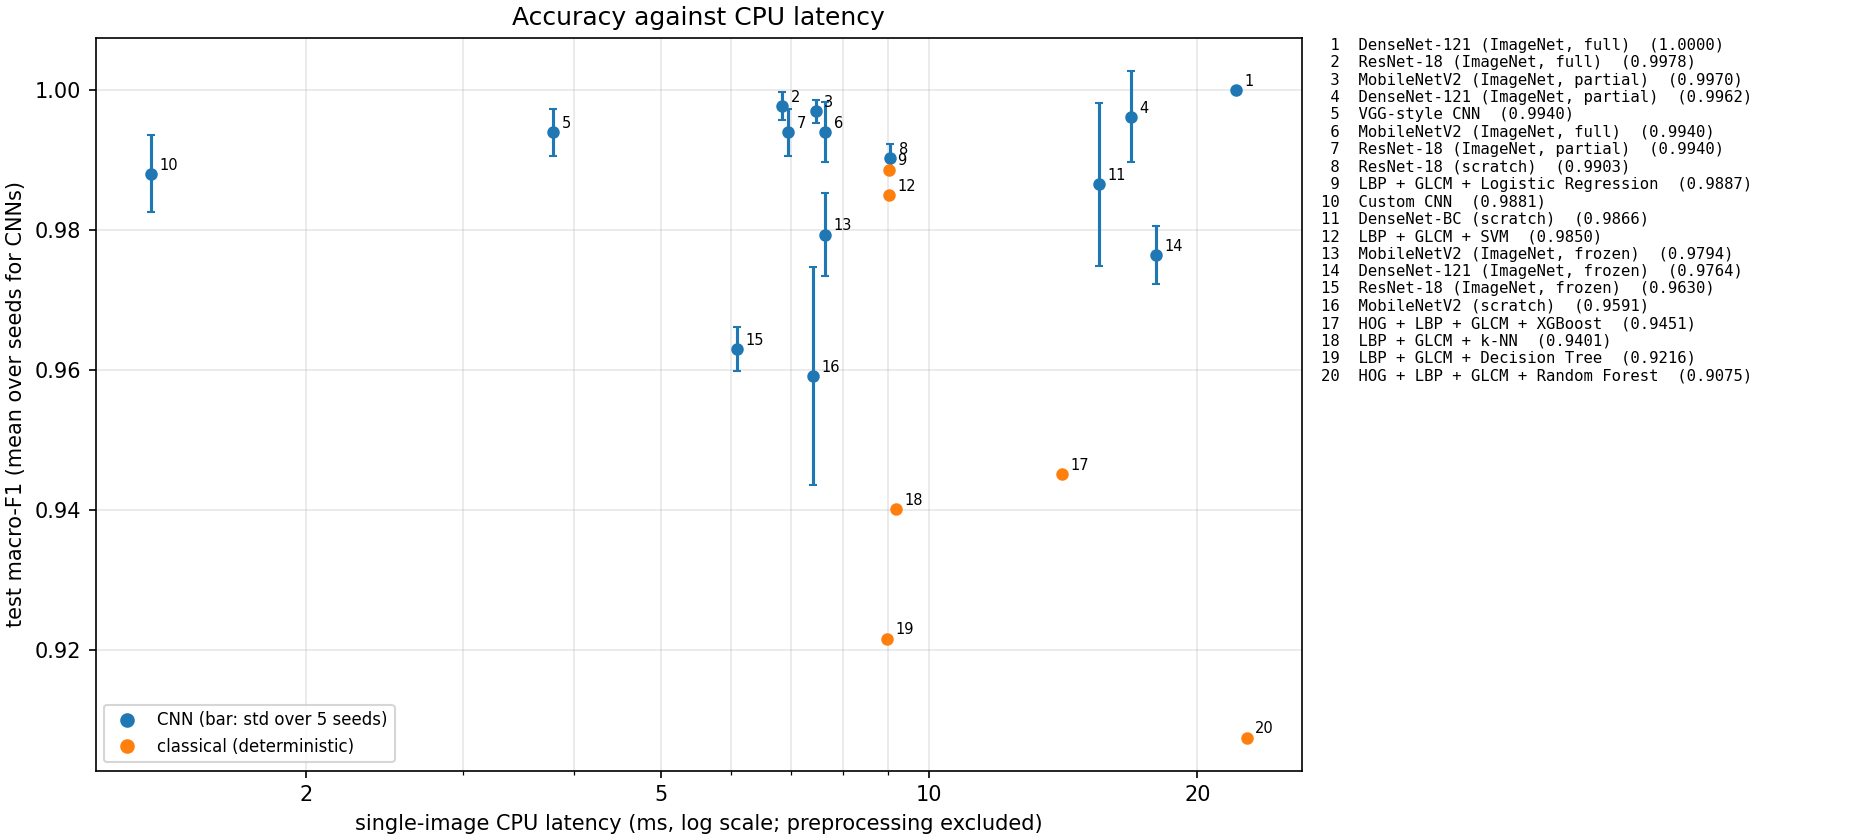

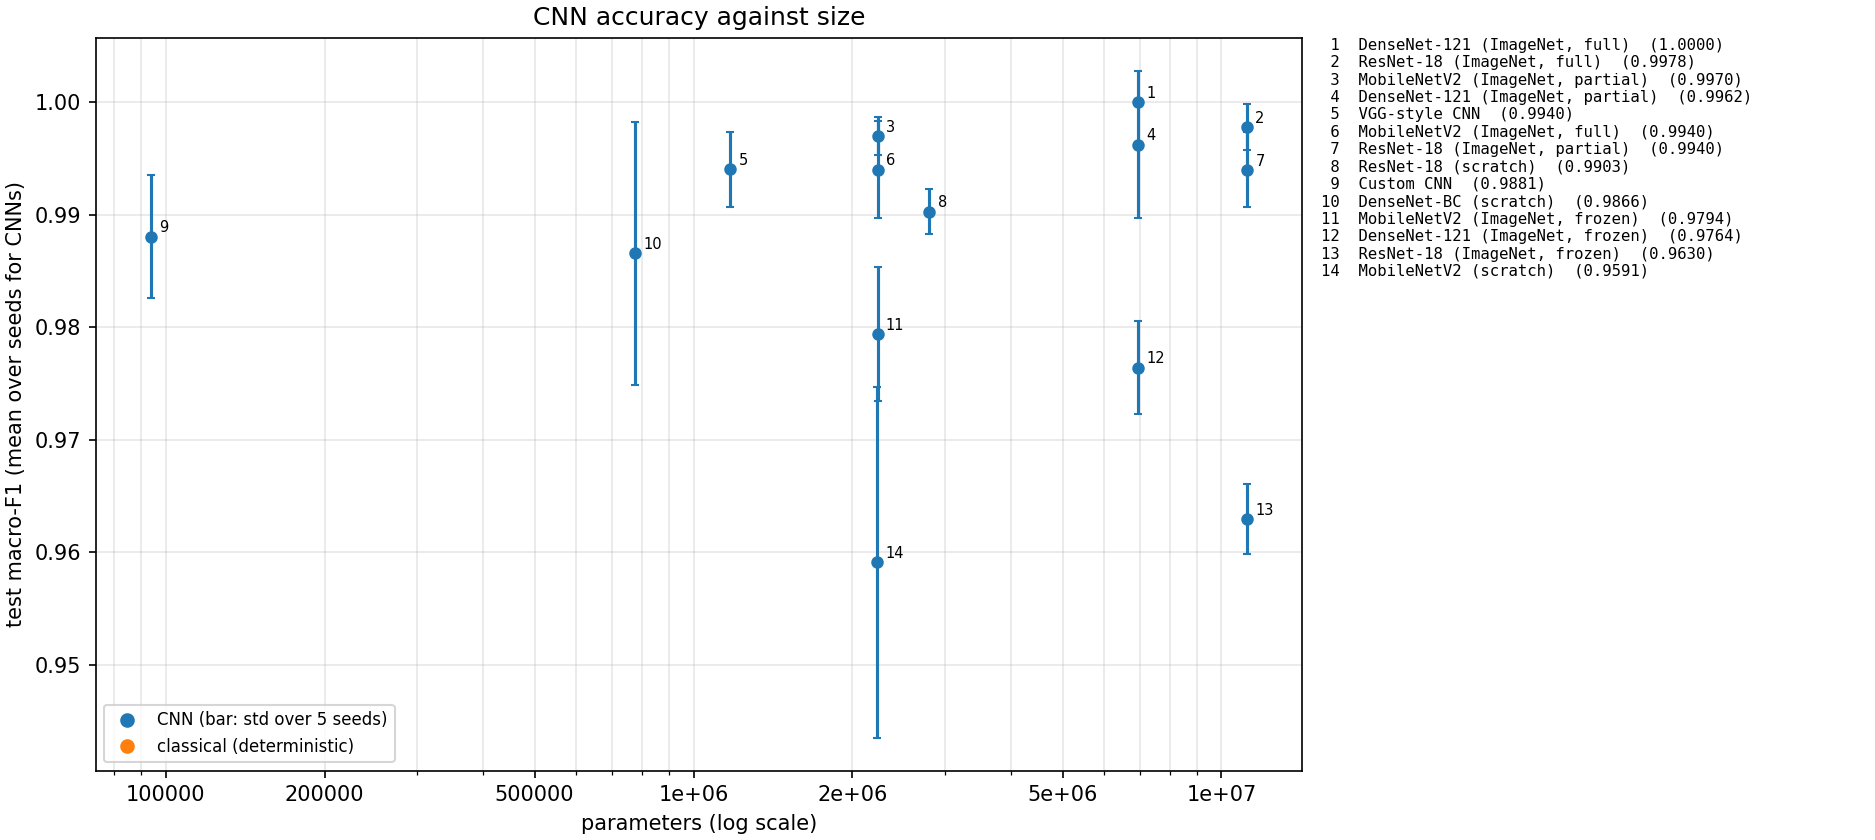

In [4]:
show(FIG / "cnn" / "accuracy_vs_cpu_latency.png")
show(FIG / "cnn" / "accuracy_vs_params.png")

* **The custom CNN is the cheapest model** (1.3 ms per image on the CPU, 0.4 MB).
* **The classical model is not cheaper**: its 9 ms are almost all LBP and GLCM feature extraction.
* **Partially fine-tuned MobileNetV2** (0.9970 at 7.5 ms) and **fully fine-tuned ResNet-18** (0.9978 at
  6.8 ms) are within one test image of the perfect DenseNet-121 at about a third of its CPU latency.

## How much data does each approach need? (validation split only, 3 seeds)

In [5]:
c = json.loads((RES / "cnn_studies" / "data_curve.json").read_text())
df = pd.DataFrame(c["summary"])
n = {r["fraction"]: r["n_train"] for r in c["rows"]}
df["training images"] = df["fraction"].map(n)
df.pivot_table(index="model", columns="training images", values="val_macro_f1_mean", sort=False).round(4)

training images,126,313,630,1260
model,,,,
custom_cnn,0.9118,0.9538,0.9637,0.9794
vgg,0.9427,0.9684,0.9842,0.9927
resnet18_imagenet (full),0.9815,0.9951,0.9988,1.0000
lbp+glcm+logreg,0.9227,0.9155,0.9242,0.9449
lbp+glcm+svm,0.8710,0.9218,0.9169,0.9340


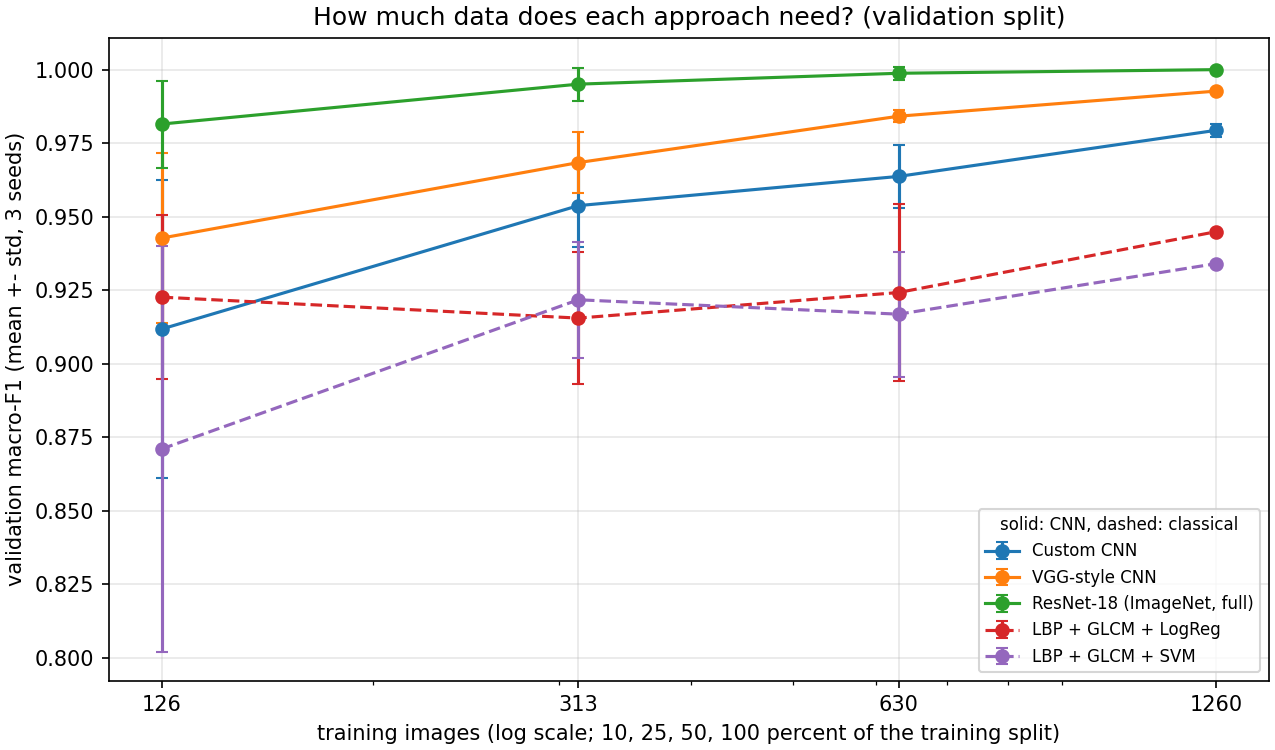

In [6]:
show(FIG / "cnn" / "data_curve.png")

* **"Handcrafted features need less data" does not hold here**: with 126 images the texture classifier
  only ties the small custom CNN, and from 313 images on every CNN is ahead.
* **The pretrained CNN is the data-efficient choice**: on 126 images it matches the custom CNN trained
  on all 1,260 (0.9815 against 0.9794).
* **Texture classifiers hardly improve with more data**: they are limited by what LBP and GLCM describe.

## Conclusion: classical versus CNN on NEU

| Question | Classical (LBP + GLCM + logistic regression) | CNN |
|---|---|---|
| Accuracy (test macro-F1) | 0.9887 | 0.9881 (custom CNN) to 1.0000 (DenseNet-121, ImageNet, full) |
| Data needed | plateaus early | keeps improving; pretrained: 0.98 with 126 images |
| Inference (CPU, one image) | 9 ms, almost all feature extraction | 1.3 ms (custom CNN) to 22 ms (DenseNet-121) |
| Interpretability | 102 named texture statistics, linear weights | Grad-CAM maps, coarse for ImageNet backbones |
| Deployment | scikit-learn, no GPU, 10 KB model | PyTorch, 0.4 to 43 MB, GPU optional |

1. Well-chosen handcrafted features are a strong, interpretable baseline that ties a small CNN.
2. A CNN from scratch is not automatically better: four of five architectures land within about two
   test images of the texture model.
3. Transfer learning is what moves the result: 0.994 to 1.000 with partial or full fine-tuning, and the
   only approach that classifies `Sc_44.bmp` correctly.
4. On a CPU, the custom CNN (1.3 ms) or partially fine-tuned MobileNetV2 (7.5 ms, 0.997) are the
   sensible deployment choices.

NEU is close to saturated for pretrained CNNs (one test image is about 0.0037 macro-F1); harder datasets
are the subject of Phase 4.